
# Assignment 7 — Learning Agent for Target Temperature Using LangGraph

### Objective
Develop a simple learning agent that learns how to maintain a target room temperature.

### Agent Approach
This assignment uses **LangGraph** to organize the learning agent as a state-based workflow.

The agent observes the temperature, chooses **Heat**, **Keep**, or **Cool**, receives a reward, updates its Q-table, and repeats the process to improve its decisions.


### Step 1 — Install and Import Libraries
LangGraph is used to build the agent workflow. Matplotlib is used for visualization.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from typing import TypedDict
from langgraph.graph import StateGraph, START, END



### Step 2 — Define the Temperature Environment

The target temperature is **22°C**. The room is divided into three states: Cold, Comfortable, and Hot.


In [2]:

TARGET_TEMP = 22.0
MIN_TEMP = 15.0
MAX_TEMP = 30.0

states = ["Cold", "Comfortable", "Hot"]
actions = ["Heat", "Keep", "Cool"]

def get_state(temperature):
    if temperature < 21:
        return "Cold"
    elif temperature > 23:
        return "Hot"
    return "Comfortable"

def get_reward(temperature):
    return 10 - abs(TARGET_TEMP - temperature)

print("Target temperature:", TARGET_TEMP, "°C")
print("States:", states)
print("Actions:", actions)


Target temperature: 22.0 °C
States: ['Cold', 'Comfortable', 'Hot']
Actions: ['Heat', 'Keep', 'Cool']


### Step 3 — Create the Q-Table
The Q-table stores the learned value of every state-action pair.

In [3]:

q_table = {
    state: {action: 0.0 for action in actions}
    for state in states
}

for state in states:
    print(state, q_table[state])


Cold {'Heat': 0.0, 'Keep': 0.0, 'Cool': 0.0}
Comfortable {'Heat': 0.0, 'Keep': 0.0, 'Cool': 0.0}
Hot {'Heat': 0.0, 'Keep': 0.0, 'Cool': 0.0}



### Step 4 — Define the LangGraph State

LangGraph passes information between nodes using a shared state.


In [4]:

class AgentState(TypedDict, total=False):
    temperature: float
    state: str
    action: str
    reward: float
    next_temperature: float
    alpha: float
    gamma: float
    epsilon: float



### Step 5 — Create the Agent Nodes

The workflow contains four simple nodes:

**Observe → Choose Action → Update Environment → Learn**


In [5]:

def observe(state):
    state["state"] = get_state(state["temperature"])
    return state


def choose_action(state):
    current_state = state["state"]
    epsilon = state["epsilon"]

    if random.random() < epsilon:
        action = random.choice(actions)
    else:
        action = max(q_table[current_state], key=q_table[current_state].get)

    state["action"] = action
    return state


def update_environment(state):
    temperature = state["temperature"]
    action = state["action"]

    if action == "Heat":
        temperature += 1.2
    elif action == "Cool":
        temperature -= 1.2

    temperature += 0.15 * (18 - temperature)
    temperature += random.uniform(-0.25, 0.25)
    temperature = max(MIN_TEMP, min(MAX_TEMP, temperature))

    state["next_temperature"] = temperature
    state["reward"] = get_reward(temperature)
    return state


def learn(state):
    current_state = state["state"]
    action = state["action"]
    next_state = get_state(state["next_temperature"])

    old_value = q_table[current_state][action]
    best_next_value = max(q_table[next_state].values())

    alpha = state["alpha"]
    gamma = state["gamma"]
    reward = state["reward"]

    q_table[current_state][action] = old_value + alpha * (
        reward + gamma * best_next_value - old_value
    )

    return state


### Step 6 — Build the LangGraph Workflow
The graph connects the agent's observation, decision, environment, and learning steps.

In [6]:

workflow = StateGraph(AgentState)

workflow.add_node("observe", observe)
workflow.add_node("choose_action", choose_action)
workflow.add_node("update_environment", update_environment)
workflow.add_node("learn", learn)

workflow.add_edge(START, "observe")
workflow.add_edge("observe", "choose_action")
workflow.add_edge("choose_action", "update_environment")
workflow.add_edge("update_environment", "learn")
workflow.add_edge("learn", END)

agent_graph = workflow.compile()

print("LangGraph workflow created successfully.")


LangGraph workflow created successfully.


### Step 7 — Train the Learning Agent
The agent initially explores many actions. Exploration gradually decreases as it learns.

In [7]:

def train_agent(episodes=100, steps_per_episode=40):
    global q_table

    q_table = {
        state: {action: 0.0 for action in actions}
        for state in states
    }

    alpha = 0.25
    gamma = 0.90
    epsilon = 1.0
    epsilon_min = 0.05
    epsilon_decay = 0.96

    episode_rewards = []

    for episode in range(episodes):
        temperature = random.uniform(16, 28)
        total_reward = 0

        for _ in range(steps_per_episode):
            state = {
                "temperature": temperature,
                "alpha": alpha,
                "gamma": gamma,
                "epsilon": epsilon
            }

            state = observe(state)
            state = choose_action(state)
            state = update_environment(state)
            state = learn(state)

            temperature = state["next_temperature"]
            total_reward += state["reward"]

        episode_rewards.append(total_reward)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    return episode_rewards, epsilon


episode_rewards, final_epsilon = train_agent()

print("Training completed.")
print("Final exploration rate:", round(final_epsilon, 3))


Training completed.
Final exploration rate: 0.05


### Step 8 — View the Learned Q-Table

In [8]:

for state in states:
    print(f"{state:12}", end="")
    for action in actions:
        print(f"{action}: {q_table[state][action]:7.2f}", end="   ")
    print()


Cold        Heat:   90.47   Keep:   88.32   Cool:   88.65   
Comfortable Heat:   93.52   Keep:   93.34   Cool:   90.88   
Hot         Heat:   92.09   Keep:   92.72   Cool:   93.70   


### Step 9 — Visualize Learning Progress

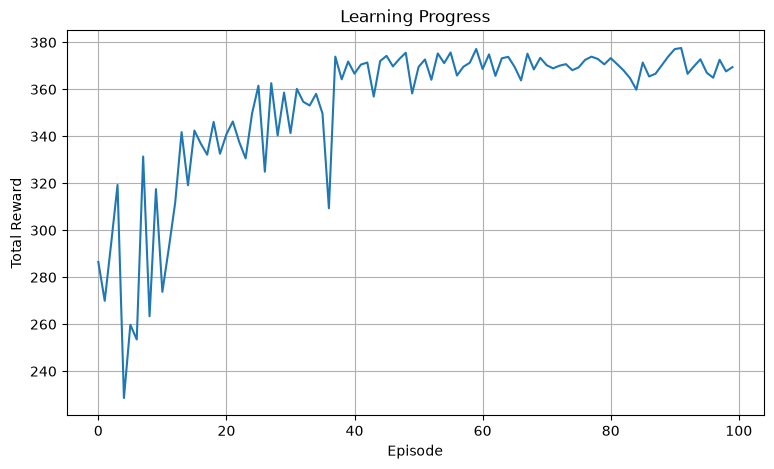

In [9]:

plt.figure(figsize=(9, 5))
plt.plot(episode_rewards)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Learning Progress")
plt.grid(True)
plt.show()


### Step 10 — Visualize the Q-Values

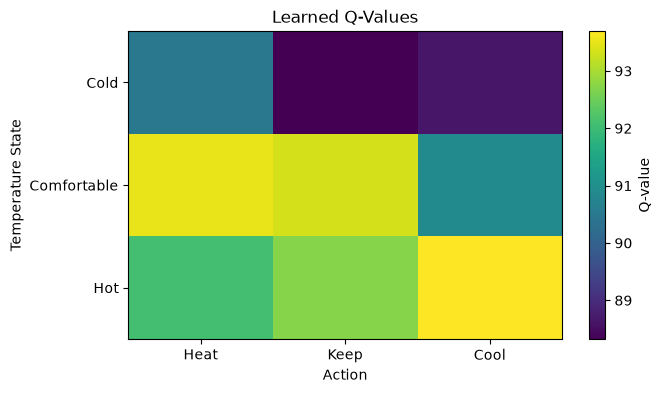

In [10]:

q_values = np.array([
    [q_table[state][action] for action in actions]
    for state in states
])

plt.figure(figsize=(7, 4))
plt.imshow(q_values, aspect="auto")
plt.xticks(range(len(actions)), actions)
plt.yticks(range(len(states)), states)
plt.xlabel("Action")
plt.ylabel("Temperature State")
plt.title("Learned Q-Values")
plt.colorbar(label="Q-value")
plt.show()



### Step 11 — Test the Learned Agent

Exploration is turned off during testing so the agent follows its learned policy.


In [11]:

def test_agent(start_temperature=27.0, steps=30):
    temperature = start_temperature
    temperatures = [temperature]
    chosen_actions = []
    rewards = []

    for _ in range(steps):
        state = {
            "temperature": temperature,
            "alpha": 0.0,
            "gamma": 0.90,
            "epsilon": 0.0
        }

        state = observe(state)
        state = choose_action(state)
        state = update_environment(state)

        temperature = state["next_temperature"]
        temperatures.append(temperature)
        chosen_actions.append(state["action"])
        rewards.append(state["reward"])

    return temperatures, chosen_actions, rewards


test_temperatures, test_actions, test_rewards = test_agent()

print("Test completed.")
print("Average test temperature:",
      round(np.mean(test_temperatures), 2), "°C")


Test completed.
Average test temperature: 22.61 °C


### Step 12 — Plot Temperature Control

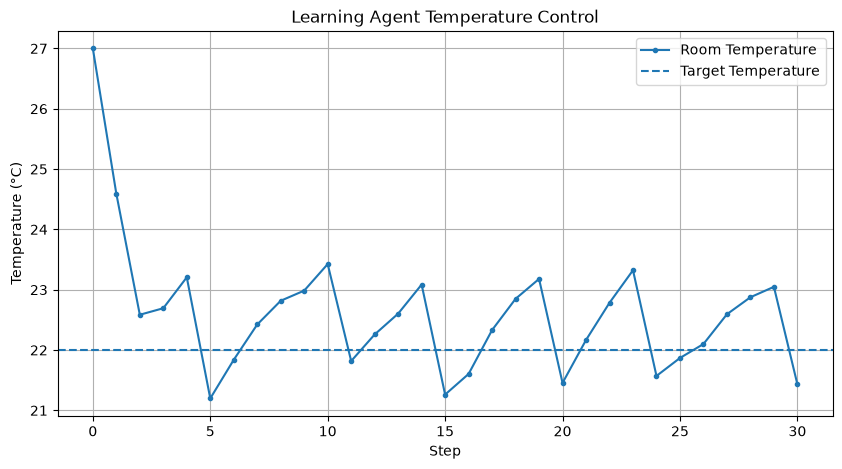

In [12]:

plt.figure(figsize=(10, 5))
plt.plot(test_temperatures, marker="o", markersize=3, label="Room Temperature")
plt.axhline(TARGET_TEMP, linestyle="--", label="Target Temperature")
plt.xlabel("Step")
plt.ylabel("Temperature (°C)")
plt.title("Learning Agent Temperature Control")
plt.legend()
plt.grid(True)
plt.show()



### Step 13 — Show the Actions Chosen by the Agent

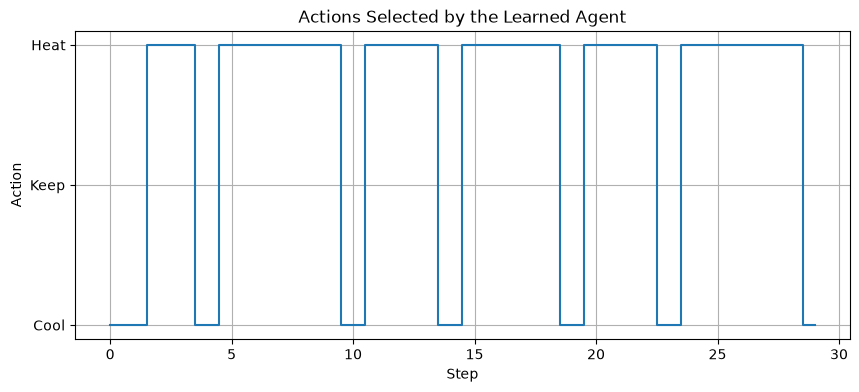

In [13]:

action_numbers = {"Heat": 1, "Keep": 0, "Cool": -1}
action_values = [action_numbers[action] for action in test_actions]

plt.figure(figsize=(10, 4))
plt.step(range(len(action_values)), action_values, where="mid")
plt.yticks([-1, 0, 1], ["Cool", "Keep", "Heat"])
plt.xlabel("Step")
plt.ylabel("Action")
plt.title("Actions Selected by the Learned Agent")
plt.grid(True)
plt.show()


### Step 14 — Display the Test Run

In [14]:

print("Step | Temperature | Action")
print("-" * 32)

for i, action in enumerate(test_actions):
    print(f"{i + 1:4} | {test_temperatures[i]:10.2f} °C | {action}")


Step | Temperature | Action
--------------------------------
   1 |      27.00 °C | Cool
   2 |      24.59 °C | Cool
   3 |      22.58 °C | Heat
   4 |      22.69 °C | Heat
   5 |      23.21 °C | Cool
   6 |      21.20 °C | Heat
   7 |      21.84 °C | Heat
   8 |      22.42 °C | Heat
   9 |      22.82 °C | Heat
  10 |      22.98 °C | Heat
  11 |      23.42 °C | Cool
  12 |      21.82 °C | Heat
  13 |      22.26 °C | Heat
  14 |      22.60 °C | Heat
  15 |      23.09 °C | Cool
  16 |      21.26 °C | Heat
  17 |      21.60 °C | Heat
  18 |      22.33 °C | Heat
  19 |      22.85 °C | Heat
  20 |      23.18 °C | Cool
  21 |      21.45 °C | Heat
  22 |      22.17 °C | Heat
  23 |      22.78 °C | Heat
  24 |      23.32 °C | Cool
  25 |      21.57 °C | Heat
  26 |      21.87 °C | Heat
  27 |      22.10 °C | Heat
  28 |      22.59 °C | Heat
  29 |      22.88 °C | Heat
  30 |      23.05 °C | Cool



### Result

The learning agent improves its decisions by interacting with the temperature environment and updating its Q-table.

### Conclusion

This assignment demonstrates a **learning agent using Q-learning and LangGraph**. LangGraph provides the workflow structure, while Q-learning allows the agent to learn suitable actions for maintaining the target temperature.

The learned policy should generally prefer **Heat** when the room is cold, **Keep** near the target, and **Cool** when the room is hot.
